In [66]:
import pandas as pd
from pathlib import Path
import numpy as np


sachs_path = Path(
    "/vol/bitbucket/ad6013/Research/CausalInferenceNeuralProcess/CITNP/datasets/synth_training_data/sachs/sachs_data_cleaned.csv"
)

In [67]:
def extract_obs_samples(sachs_data: pd.DataFrame, num_samples: int):
    """
    Extract observational samples from the Sachs dataset.
    """
    obs_samples = sachs_data[sachs_data["intervention_name"] == "obs"]
    data_columns = obs_samples.iloc[:, :11].to_numpy()
    return data_columns[:num_samples]


def extract_int_samples(sachs_data: pd.DataFrame, intvn: str):
    """
    Extract interventional samples from the Sachs dataset.
    """
    int_samples = sachs_data[sachs_data["intervention_name"] == intvn]
    data_columns = int_samples.iloc[:, :11].to_numpy()
    return data_columns

In [68]:
all_datasets = []

sachs = pd.read_csv(sachs_path)

# Extract 750 samples of obs data
sachs_obs = extract_obs_samples(sachs, 750)

# We need a differnt dataset for each interventional data
unique_int = sachs["intervention_name"].unique()
for intvn in unique_int:
    if intvn == "obs":
        continue
    final_dataset = {}

    final_dataset["obs_data"] = sachs_obs[None]

    sachs_int = extract_int_samples(sachs, intvn)

    final_dataset["int_data"] = sachs_int[None]

    # Find the intervention index
    intvn_index = sachs.columns.get_loc(intvn)
    intvn_index = np.array([intvn_index])[None]

    final_dataset["intvn_indices"] = intvn_index

    variable_counts = np.array([sachs.shape[1]])[None]
    final_dataset["variable_counts"] = variable_counts

    causal_graph = np.zeros((sachs.shape[1], sachs.shape[1]))[None]
    final_dataset["causal_graphs"] = causal_graph

    all_datasets.append(final_dataset)

In [69]:
import h5py


save_path = Path(
    "/vol/bitbucket/ad6013/Research/CausalInferenceNeuralProcess/CITNP/datasets/synth_training_data/sachs/test"
)
save_path.mkdir(parents=True, exist_ok=True)


for idx, dataset in enumerate(all_datasets):
    with h5py.File(f"{save_path}/data_idx{idx}.hdf5", "w") as f:
        for key, value in dataset.items():
            if value is None:
                continue
            f.create_dataset(key, data=value)


In [1]:
import h5py
from pathlib import Path


sachs_path = Path(
    "/vol/bitbucket/ad6013/Research/CausalInferenceNeuralProcess/CITNP/datasets/synth_training_data/sachs/test"
    )
interventions = [
    "data_idx0",
    "data_idx1",
    "data_idx2",
    "data_idx3",
    "data_idx4",
]

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import StandardScaler

def plot_for_file(sachs_path, sachs_file, outcome_index):

    with h5py.File(sachs_path / f"{sachs_file}.hdf5", "r") as f:
        sachs_obs_data = f["obs_data"][:]
        sachs_int_data = f["int_data"][:]
        sachs_causal_graphs = f["causal_graphs"][:]
        sachs_intvn_indices = f["intvn_indices"][:]
        sachs_variable_counts = f["variable_counts"][:]
        f.close()
    # Identify the intervention index and set the outcome index
    intvn_index = sachs_intvn_indices[0][0]
    if intvn_index == outcome_index:
        outcome_index += 1

    print(f"Outcome index: {outcome_index}")
    print(f"Intervention index: {intvn_index}")

    # Extract the data for plotting (first 500 samples, variables outcome_index and intvn_index)
    obs_data_subset = sachs_obs_data[:, :500, [outcome_index, intvn_index]]
    int_data_subset = sachs_int_data[:, :500, [outcome_index, intvn_index]]
    obs_data_subset = obs_data_subset[0]
    int_data_subset = int_data_subset[0]
    print(f"Observational data shape: {obs_data_subset.shape}")
    print(f"Interventional data shape: {int_data_subset.shape}")

    # Create copies of the data for normalization
    int_data_norm = int_data_subset.copy()

    # Normalize BOTH variables in observational data
    obs_scaler = StandardScaler()
    obs_data_norm = obs_scaler.fit_transform(obs_data_subset)

    int_data_subset = obs_scaler.transform(int_data_subset)


    int_scaler = StandardScaler()
    norm_copy = int_data_subset.copy()
    int_data_notused = int_scaler.fit_transform(norm_copy)

    # Extract scalers for individual variables from the observational data
    outcome_mean = int_scaler.mean_[0]
    outcome_std = int_scaler.scale_[0]
    intvn_mean = int_scaler.mean_[1]
    intvn_std = int_scaler.scale_[1]

    # For interventional data, ONLY normalize the intervention index column (column 1)
    # Keep outcome variable (column 0) in original scale
    # int_data_norm[:, 1] = (int_data_subset[:, 1] - intvn_mean) / intvn_std
    int_data_norm = int_data_subset

    # Create a figure with two subplots side by side
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Print normalization statistics
    print(f"\nNormalization statistics from observational data:")
    print(f"Variable {outcome_index} - Mean: {outcome_mean:.4f}, Std: {outcome_std:.4f}")
    print(f"Variable {intvn_index} - Mean: {intvn_mean:.4f}, Std: {intvn_std:.4f}")

    # Plot 1: Fully normalized observational data
    ax1.scatter(obs_data_norm[:, 1], obs_data_norm[:, 0], alpha=0.7, color='blue')
    ax1.set_title('Observational Data (Both Variables Normalized)')
    ax1.set_xlabel(f'Variable {intvn_index} (Normalized)')
    ax1.set_ylabel(f'Variable {outcome_index} (Normalized)')
    ax1.grid(True, linestyle='--', alpha=0.6)

    # Plot 2: Interventional data with only intervention variable normalized
    scatter = ax2.scatter(int_data_norm[:, 1], int_data_subset[:, 0], alpha=0.7, color='red')
    ax2.set_title('Interventional Data (Only Intervention Variable Normalized)')
    ax2.set_xlabel(f'Variable {intvn_index} (Normalized)')
    ax2.set_ylabel(f'Variable {outcome_index} (Original Scale)')
    ax2.grid(True, linestyle='--', alpha=0.6)

    # Add figure title
    fig.suptitle(f'Comparison: Intervention on Variable {intvn_index}, Effect on Variable {outcome_index}', fontsize=14)

    # Add info about the normalization
    plt.figtext(0.5, 0.01,
            f"Note: Obs data fully normalized; Int data has only Variable {intvn_index} normalized",
            ha="center", fontsize=10, bbox={"facecolor":"lightgray", "alpha":0.5, "pad":5})

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # Adjust layout to make room for the note
    plt.show()



Outcome index: 6
Intervention index: 5
Observational data shape: (500, 2)
Interventional data shape: (500, 2)

Normalization statistics from observational data:
Variable 6 - Mean: 0.2110, Std: 1.1058
Variable 5 - Mean: 0.2449, Std: 0.9576


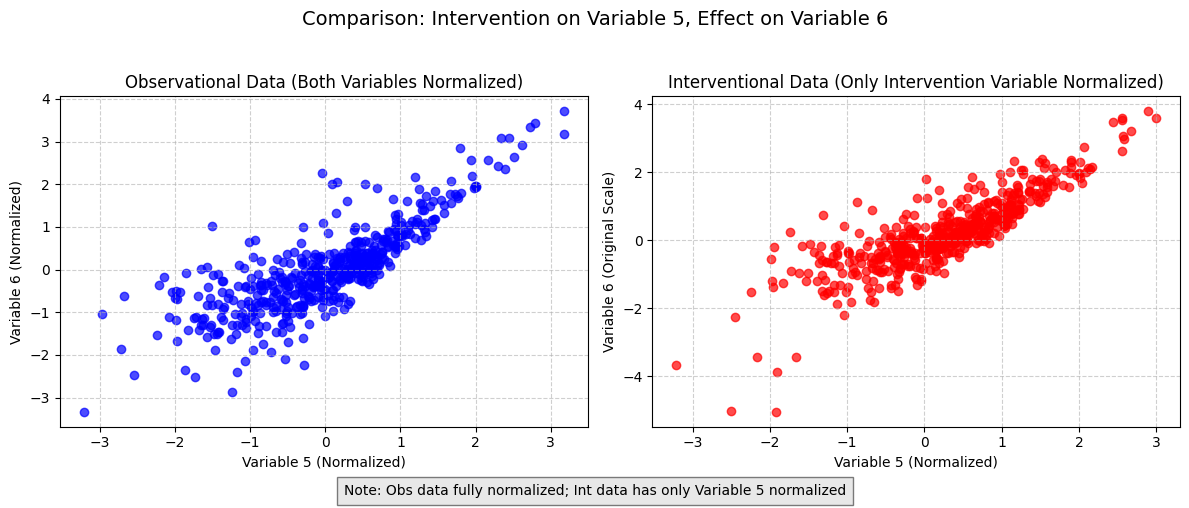

Outcome index: 5
Intervention index: 7
Observational data shape: (500, 2)
Interventional data shape: (500, 2)

Normalization statistics from observational data:
Variable 5 - Mean: 1.5691, Std: 0.8174
Variable 7 - Mean: -4.9827, Std: 1.1776


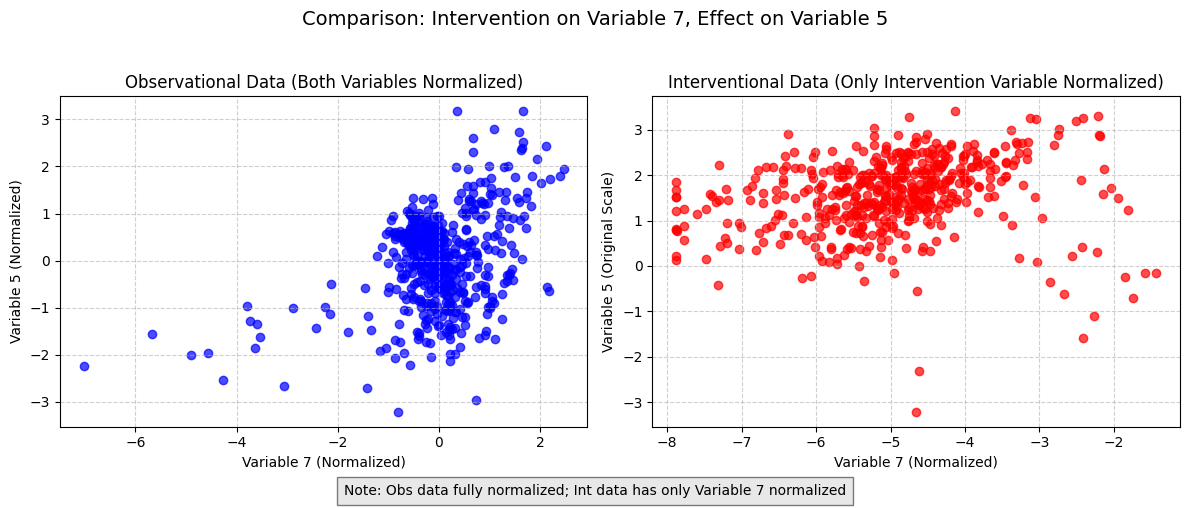

Outcome index: 5
Intervention index: 2
Observational data shape: (500, 2)
Interventional data shape: (500, 2)

Normalization statistics from observational data:
Variable 5 - Mean: 0.5454, Std: 0.9421
Variable 2 - Mean: -1.6706, Std: 1.0736


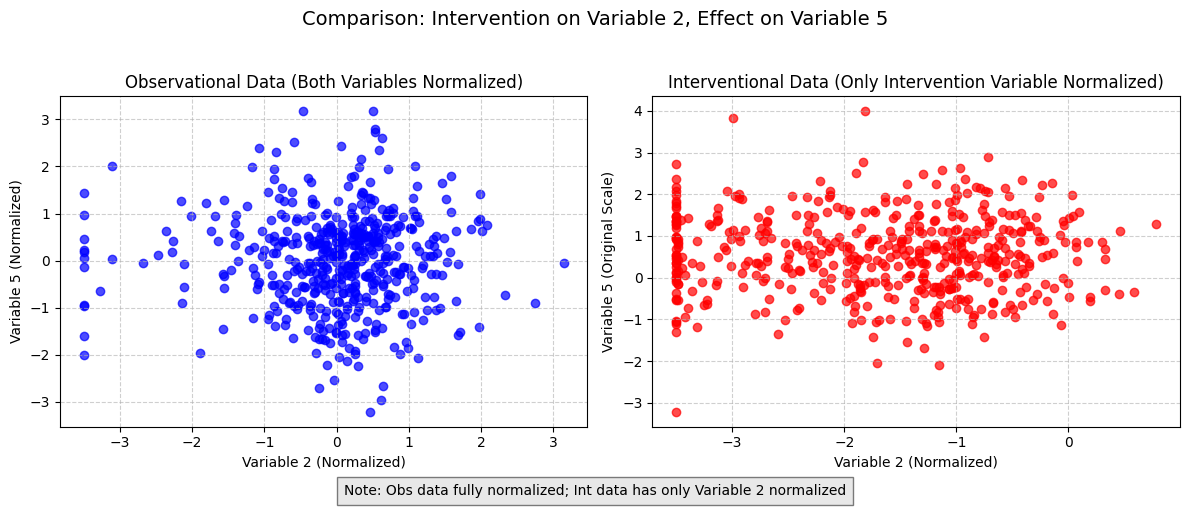

Outcome index: 5
Intervention index: 0
Observational data shape: (500, 2)
Interventional data shape: (500, 2)

Normalization statistics from observational data:
Variable 5 - Mean: -1.7572, Std: 1.3102
Variable 0 - Mean: 2.2639, Std: 1.5431


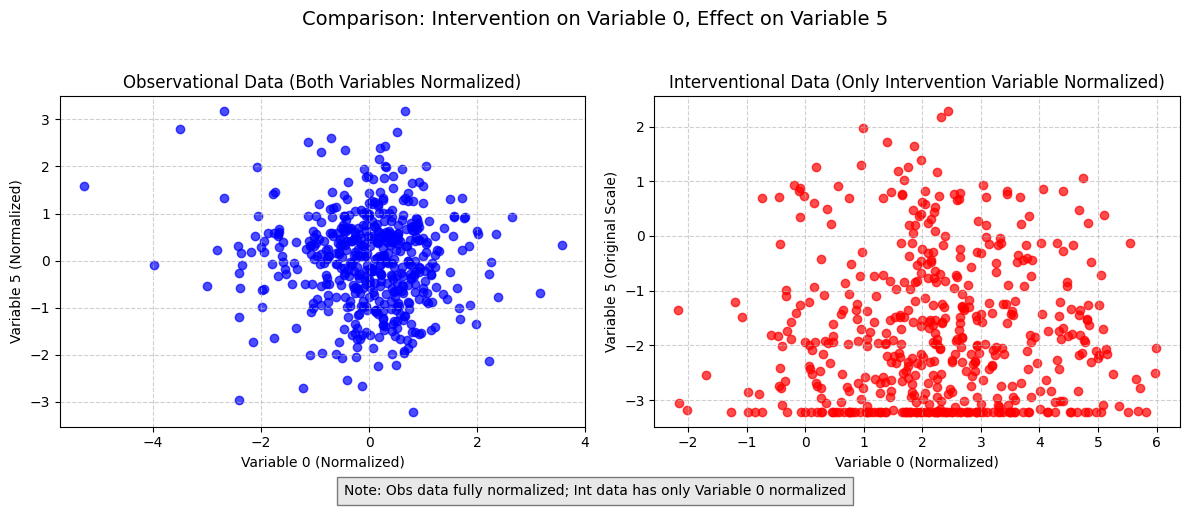

Outcome index: 5
Intervention index: 3
Observational data shape: (500, 2)
Interventional data shape: (500, 2)

Normalization statistics from observational data:
Variable 5 - Mean: -0.1751, Std: 0.9276
Variable 3 - Mean: -0.0949, Std: 1.0866


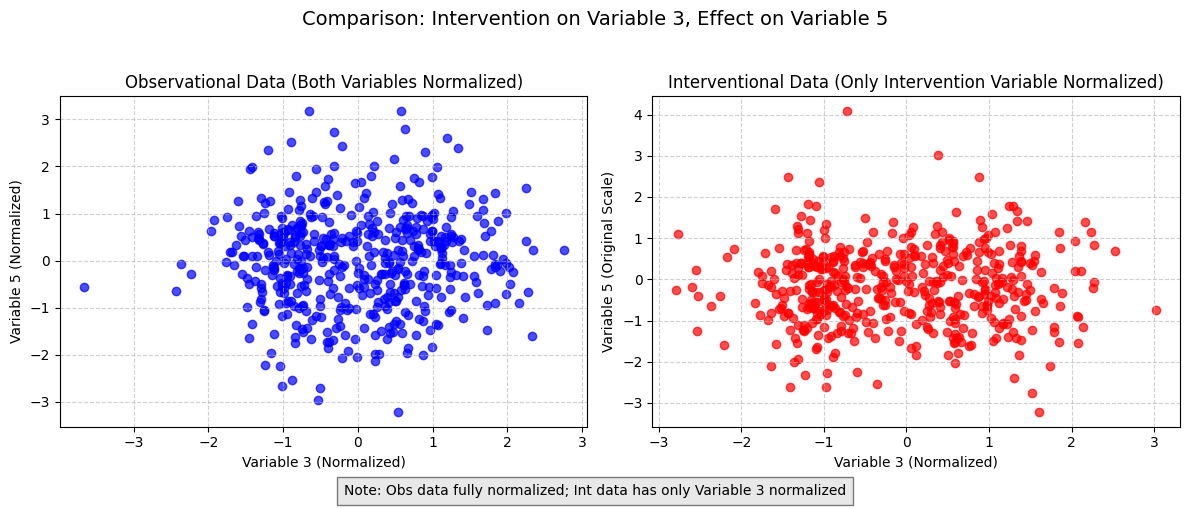

In [35]:
for intvn in interventions:
    plot_for_file(sachs_path, intvn, 5)

In [25]:
norm_copy.mean(0)

NameError: name 'norm_copy' is not defined

In [25]:
sachs_obs_data_cols = sachs_obs.iloc[:, :11]

In [26]:
sachs_obs_data_numpy = sachs_obs_data_cols.to_numpy()

In [28]:
# Take the first 750 samples
sachs_obs_data_numpy_samples = sachs_obs_data_numpy[:750]

In [ ]:
all_interventions = sachs["intervention_name"].unique()
intervention_dict = {}
for intervention in all_interventions:
    if intervention == "obs":
        continue
    interventions = sachs[sachs["intervention_name"] == intervention]
    interventions_datacols = interventions.iloc[:, :11].to_numpy()
    intervention_dict[intervention] = interventions_datacols


In [35]:
[v.shape[0] for k,v in intervention_dict.items()]

[910, 723, 810, 799, 848]

In [ ]:
import requests
import pandas as pd


url = "https://www.bnlearn.com/book-crc/code/sachs.data.txt.gz"
# You can choose the name and path for the downloaded file
file_name = "sachs.data.txt.gz"

print(f"Downloading {file_name} from {url}...")

# Send a GET request to the URL
response = requests.get(url, stream=True)

# Raise an exception if the request was unsuccessful (e.g., 404 Not Found)
response.raise_for_status()

# Open the local file in write-binary mode
with open(file_name, 'wb') as f:
    # Iterate over the response data in chunks and write to file
    for chunk in response.iter_content(chunk_size=8192):
        f.write(chunk)

print(f"File '{file_name}' downloaded successfully.")

File 'sachs.data.txt.gz' downloaded successfully.


In [10]:
df['INT'].unique()

array([8, 0, 7, 9, 4, 2])

In [1]:
import cdt
data, graph = cdt.data.load_dataset('sachs')

Detecting 1 CUDA device(s).


In [3]:
data

,praf,pmek,plcg,PIP2,PIP3,p44/42,pakts473,PKA,PKC,P38,pjnk
0,26.4,13.20,8.82,18.30,58.80,6.61,17.0,414.0,17.00,44.90,40.00
1,35.9,16.50,12.30,16.80,8.13,18.60,32.5,352.0,3.37,16.50,61.50
2,59.4,44.10,14.60,10.20,13.00,14.90,32.5,403.0,11.40,31.90,19.50
3,73.0,82.80,23.10,13.50,1.29,5.83,11.8,528.0,13.70,28.60,23.10
4,33.7,19.80,5.19,9.73,24.80,21.10,46.1,305.0,4.66,25.70,81.30
...,...,...,...,...,...,...,...,...,...,...,...
7461,49.1,12.40,32.80,27.90,22.70,11.70,38.2,1144.0,1.00,2.55,1.00
7462,23.3,4.61,17.80,22.10,14.90,48.70,67.3,922.0,1.00,9.82,1.00
7463,28.1,4.49,18.80,20.20,10.20,3.08,21.9,730.0,1.00,1.75,2.00
7464,34.6,7.10,5.73,20.70,15.10,32.20,41.4,813.0,44.50,1382.00,2.44
